In [ ]:
!pip install pennylane scikit-learn pandas numpy matplotlib seaborn

# Biblio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pennylane as qml

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Network data

In [ ]:
# 1. data generation
X_raw, Y_raw=make_classification(
    n_samples=200,
    n_features=10,
    n_informative=6,
    n_classes=2,
    random_state=42
)
# 2. Separation Train / Test
X_train_raw, X_test_raw, Y_train, Y_test= train_test_split( X_raw, Y_raw, test_size=0.3, random_state=42, stratify=Y_raw)

# 3. Standarization
scaler = StandardScaler()
X_train_scaled= scaler.fit_transform(X_train_raw)
X_test_scaled= scaler.transform(X_test_raw)

# 4. Dimension reduction
N_QUBITS = 4
pca = PCA(n_components=N_QUBITS)
X_train_pca=pca.fit_transform(X_train_scaled)
X_test_pca= pca.fit_transform(X_test_scaled)

# 5. Normalisation  of angles for quantum encoding
X_train_q=np.pi* (X_train_pca - X_train_pca.min()) / (X_train_pca.max() - X_train_pca.min())
X_test_q=np.pi* (X_test_pca -X_test_pca.min())/ (X_test_pca.max()-X_test_pca.min())

print(f"Training data dimension :  {X_train_q.shape}")



Training data dimension :  (140, 4)


# Construction of the Quantum Circuit and the Quantum Kernel

In [ ]:
# Quantum processor initialisation
dev= qml.device("default.qubit", wires=N_QUBITS)

# Feature Map circuit
def feature_map(x):
  # Encoding with angle rotation (Angle Embedding)
  for i in range(N_QUBITS):
    qml.RY(x[i], wires=i)

  # Entinglement layer
  for i in range(N_QUBITS-1):
    qml.CNOT(wires=[i,i+1])
    qml.RZ(x[i] * x[i+1], wires=i+1)
    qml.CNOT(wires=[i, i+1])

@qml.qnode(dev)
def kernel_circuit(x1, x2):
  # Apply U(x1)
  feature_map(x1)

  # Apply inverse
  qml.adjoint(feature_map)(x2)

  #
  return qml.probs(wires=range(N_QUBITS))

def compute_quantum_kernel_entry(x1, x2):
  return kernel_circuit(x1, x2)[0]

def compute_kernel_matrix(X1,X2):

  matrix=np.zeros((len(X1), len(X2)))

  for i in range(len(X1)):
    for j in range(len(X2)):
      matrix[i,j]=compute_quantum_kernel_entry(X1[i], X2[j])
  return matrix

# Gram Matrix

In [ ]:
print("Calculation of the quantum kernel matrix for traingin(Gram Matrix)")
K_train=compute_kernel_matrix(X_train_q, X_train_q)
print("Calculation of the quantum kernel matrix for testing(Gram Matrix)")
k_test=compute_kernel_matrix(X_test_q, X_train_q)

Calculation of the quantum kernel matrix for traingin(Gram Matrix)
Calculation of the quantum kernel matrix for testing(Gram Matrix)


# Visulatisation de la matrice de Gram

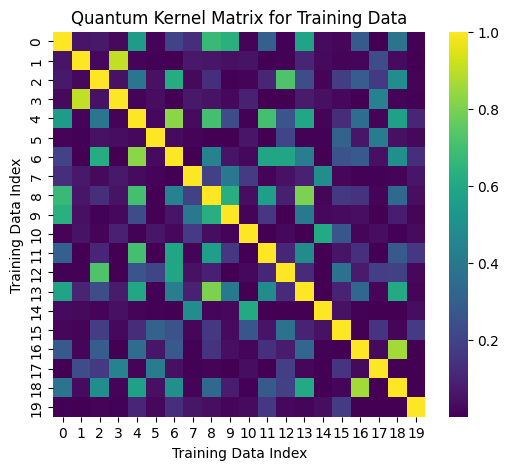

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(K_train[:20, :20], cmap="viridis" , annot=False)
plt.title("Quantum Kernel Matrix for Training Data")
plt.xlabel("Training Data Index")
plt.ylabel("Training Data Index")
plt.show()

#  QSVM classifier


=== ÉVALUATION DE LA DÉTECTION D'INTRUSIONS (QSVM) ===
Précision globale (Accuracy) : 56.67%

Rapport de classification détaillé :
                      precision    recall  f1-score   support

Trafic Sain (Normal)       0.58      0.47      0.52        30
 Intrusion (Attaque)       0.56      0.67      0.61        30

            accuracy                           0.57        60
           macro avg       0.57      0.57      0.56        60
        weighted avg       0.57      0.57      0.56        60



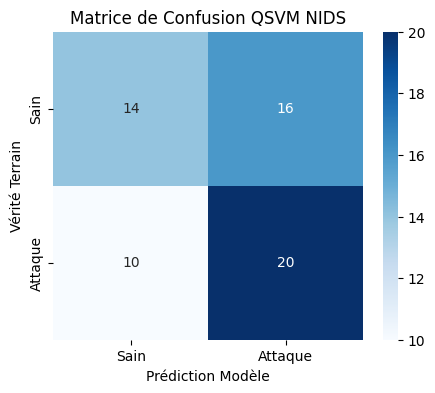

In [ ]:
qsvm=SVC(kernel="precomputed")
qsvm.fit(K_train,Y_train)

y_pred=qsvm.predict(k_test)

print("\n=== ÉVALUATION DE LA DÉTECTION D'INTRUSIONS (QSVM) ===")
print(f"Précision globale (Accuracy) : {accuracy_score(Y_test, y_pred) * 100:.2f}%\n")
print("Rapport de classification détaillé :")
print(classification_report(Y_test, y_pred, target_names=["Trafic Sain (Normal)", "Intrusion (Attaque)"]))

# Matrice de confusion
cm = confusion_matrix(Y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Sain", "Attaque"],
            yticklabels=["Sain", "Attaque"])
plt.xlabel("Prédiction Modèle")
plt.ylabel("Vérité Terrain")
plt.title("Matrice de Confusion QSVM NIDS")
plt.show()